In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional

class Detector:
    """
    Класс, описывающий сферический жидкосцинтилляционный детектор.
    """
    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.1, a: float = 0.5):
        """
        Инициализация детектора.

        Параметры:
        R -- радиус детектора в метрах
        N -- количество фотоумножителей
        r -- радиус фотокатода ФЭУ в метрах (10 см = 0.1 м)
        a -- вероятность выбивания хотя бы одного фотоэлектрона
        """
        self.R = R
        self.N = N
        self.r = r  # Перевели 10 см в метры
        self.a = a

        # Генерируем координаты ФЭУ при создании объекта
        self.pmt_coords = self._generate_pmt_coordinates()

    def _generate_pmt_coordinates(self) -> np.ndarray:
        """
        Равномерно располагает N фотоумножителей на поверхности сферы.
        Использует метод спирали Фибоначчи.
        Возвращает массив numpy формы (N, 3) с координатами (x, y, z).
        """
        indices = np.arange(0, self.N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / self.N) # Полярный угол
        theta = np.pi * (1 + 5**0.5) * indices    # Азимутальный угол (золотое сечение)

        x = self.R * np.cos(theta) * np.sin(phi)
        y = self.R * np.sin(theta) * np.sin(phi)
        z = self.R * np.cos(phi)

        return np.column_stack((x, y, z))

    def find_pmt(self, point: np.ndarray) -> Optional[int]:
        """
        Определяет, принадлежит ли точка на поверхности детектора какому-либо ФЭУ.

        Параметры:
        point -- координаты точки (x, y, z) на сфере

        Возвращает:
        Индекс ФЭУ, которому принадлежит точка, или None, если точка не попала ни в один ФЭУ.
        """
        # Считаем расстояние от заданной точки до центров всех ФЭУ
        # Векторизованная операция numpy
        distances = np.linalg.norm(self.pmt_coords - point, axis=1)

        # Находим индексы ФЭУ, в которые попала точка (расстояние меньше радиуса ФЭУ)
        hit_indices = np.where(distances <= self.r)[0]

        if len(hit_indices) > 0:
            return hit_indices[0] # Возвращаем первый найденный (если попали в стык)
        return None

    def visualize_geometry(self):
        """
        Визуализирует геометрию детектора с помощью matplotlib.
        """
        fig = plt.figure(figsize=(8, 8))
        ax = fig.add_subplot(111, projection='3d')

        # Рисуем каркас сферы (сам детектор)
        u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
        x = self.R * np.cos(u)*np.sin(v)
        y = self.R * np.sin(u)*np.sin(v)
        z = self.R * np.cos(v)
        ax.plot_wireframe(x, y, z, color="lightgray", alpha=0.5, label='Детектор')

        # Рисуем ФЭУ
        ax.scatter(self.pmt_coords[:, 0], self.pmt_coords[:, 1], self.pmt_coords[:, 2],
                   color='red', s=50, label='ФЭУ')

        ax.set_xlabel('X (м)')
        ax.set_ylabel('Y (м)')
        ax.set_zlabel('Z (м)')
        ax.set_title('Геометрия детектора')
        ax.legend()
        plt.show()

Координаты первых 3-х ФЭУ:
 [[ 0.16104292 -0.41420427  1.95      ]
 [-0.68149594  0.33624883  1.85      ]
 [ 0.92965601  0.27062835  1.75      ]]


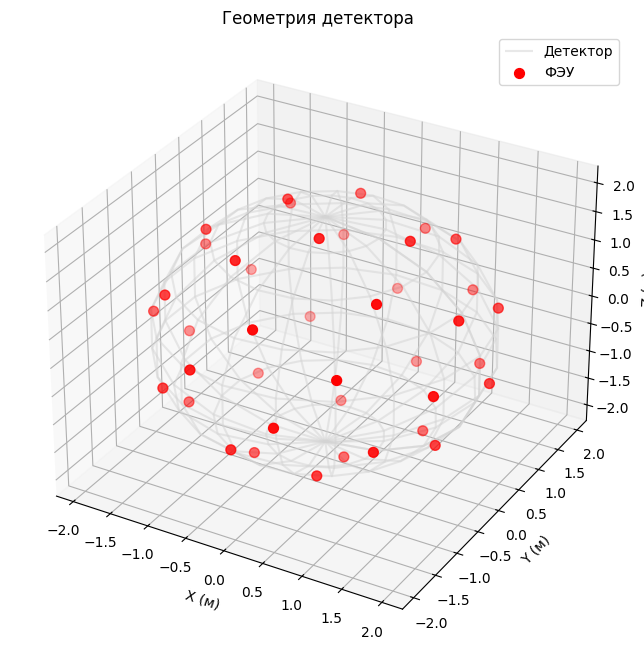

Тест 1 (центр ФЭУ): 0
Тест 2 (полюс): None
Тест 3 (случайная точка): индекс = None


In [2]:
# Создаем детектор с параметрами из задания
det = Detector(R=2.0, N=40, r=0.1, a=0.5)

# Выведем координаты первых трех ФЭУ для проверки
print("Координаты первых 3-х ФЭУ:\n", det.pmt_coords[:3])

# Визуализируем
det.visualize_geometry()

# Проверка метода find_pmt
# Возьмем точку, которая точно совпадает с центром нулевого ФЭУ
test_point_1 = det.pmt_coords[0]
print(f"Тест 1 (центр ФЭУ): {det.find_pmt(test_point_1)}") # Должно вернуть 0

# Возьмем точку, которая точно находится между ФЭУ (например, на полюсе, если там нет ФЭУ)
test_point_2 = np.array([0.0, 0.0, det.R])
print(f"Тест 2 (полюс): {det.find_pmt(test_point_2)}") # Скорее всего вернет None

# Сгенерируем случайную точку и проверим
random_point = np.random.randn(3)
random_point = random_point / np.linalg.norm(random_point) * det.R # Нормируем на радиус сферы
print(f"Тест 3 (случайная точка): индекс = {det.find_pmt(random_point)}")

# Задача 1. Создание детектора

В данном ноутбуке реализован класс `Detector` для моделирования сферического жидкосцинтилляционного детектора.
Фотоумножители (ФЭУ) расположены равномерно по поверхности сферы с помощью спирали Фибоначчи.
Также реализован метод `find_pmt` для проверки попадания точки в ФЭУ и метод визуализации геометрии с помощью `matplotlib`.